# Analyse du domaine public records

On part des 9 fichiers nettoyés dans `02_public_records_nettoyage.ipynb`. L'analyse est en trois parties :
- partie Yannis : accès aux sites, dossiers réglementaires, entités, nominations publiques et documents ;
- partie Dali : mémos, établissements, professionnels et dirigeants des sociétés ;
- retour sur nos pistes : ce que ces fichiers répondent aux questions laissées par la santé et l'écologie.

On garde le code de Yannis et de Dali. Les corrections sont signalées par « Correction ».

In [1]:
import re
import difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from pathlib import Path

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 1000)

D = Path("data_clean/public_records")
sace = pd.read_csv(D / "site_access_case_events.csv", parse_dates=["event_time"])
rce = pd.read_csv(D / "regulatory_case_events.csv", parse_dates=["event_time"])
ent = pd.read_csv(D / "registered_entities.csv", parse_dates=["registration_date", "last_filing_date"])
pa = pd.read_csv(D / "public_appointments.csv", parse_dates=["appointment_start", "appointment_end"])
paid = pd.read_csv(D / "public_and_investigative_documents.csv", parse_dates=["document_date"])
im = pd.read_csv(D / "institutional_memos.csv", parse_dates=["document_date"])
lf = pd.read_csv(D / "licensed_facilities.csv", parse_dates=["license_start", "license_end"])
lp = pd.read_csv(D / "licensed_professionals.csv", parse_dates=["license_issue_date", "license_expiry_date"])
of = pd.read_csv(D / "officer_filings.csv", parse_dates=["appointment_date", "cessation_date", "filing_date"])

# le niveau de visibilité des mémos est ordonné (une information perdue dans le fichier CSV)
im["visibility_level"] = pd.Categorical(im["visibility_level"], categories=["internal", "confidential", "restricted"], ordered=True)
ref_date = pd.Timestamp("2026-01-01")

## Partie Yannis

### 1. La durée des mandats publics

Dans `public_appointments`, on calcule la durée de chaque mandat (jusqu'au 1er janvier 2026 s'il est encore en cours), puis on cherche les valeurs hors norme.

**Correction** : le z-score modifié était calculé avec l'écart absolu moyen. La bonne formule utilise la médiane des écarts (MAD) et le coefficient 0,6745 : z = 0,6745 × (x − médiane) / MAD. On considère une valeur hors norme au-delà de 3,5.

In [2]:
pa["effective_end"] = pa["appointment_end"].fillna(ref_date)
pa["mandate_duration_years"] = (pa["effective_end"] - pa["appointment_start"]).dt.days / 365.25
pa["age_at_end_or_2026"] = pa["effective_end"].dt.year - pa["recorded_birth_year"]

# résumé statistique
def stats_and_outliers(df, col):
    s = df[col].dropna().astype(float)
    mean, std = s.mean(), s.std()
    med, q1, q3 = s.median(), s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    mad = np.median(np.abs(s - med))   # médiane des écarts à la médiane

    print(f"=== {col} (n={len(s)}) ===")
    print(f"  Moyenne : {mean:.2f} | Écart-type : {std:.2f}")
    print(f"  Médiane : {med:.2f} | Min : {s.min():.2f} | Max : {s.max():.2f} | Q1 : {q1:.2f} | Q3 : {q3:.2f} | IQR : {iqr:.2f}")

    # Détection d'outliers par IQR, Z-score (>2.5) et Z-score modifié (>3.5)
    iqr_mask = (df[col] < (q1 - 1.5 * iqr)) | (df[col] > (q3 + 1.5 * iqr))
    z_score = (df[col] - mean) / std
    mod_z_score = 0.6745 * (df[col] - med) / mad

    outliers = df[iqr_mask | (z_score.abs() > 2.5) | (mod_z_score.abs() > 3.5)].copy()
    outliers["z_score"] = z_score.round(2)
    outliers["mod_z_score"] = mod_z_score.round(2)
    return outliers[["office_holder_name", "office_title", "institution_name", col, "is_active_mandate", "z_score", "mod_z_score"]]

print(stats_and_outliers(pa, "age_at_appointment"))
print("\n", stats_and_outliers(pa, "mandate_duration_years"))

=== age_at_appointment (n=56) ===
  Moyenne : 28.52 | Écart-type : 5.34
  Médiane : 28.00 | Min : 23.00 | Max : 48.00 | Q1 : 24.00 | Q3 : 31.00 | IQR : 7.00
   office_holder_name              office_title                institution_name  age_at_appointment  is_active_mandate  z_score  mod_z_score
12       Mirek Talven  Deputy regional governor  Tembara Coastal Administration                48.0              False     3.65         4.50
15         Elira Vaun         Council president        Avelora Council of State                45.0              False     3.09         3.82
=== mandate_duration_years (n=62) ===
  Moyenne : 19.10 | Écart-type : 13.59
  Médiane : 14.33 | Min : 1.00 | Max : 56.71 | Q1 : 9.00 | Q3 : 27.25 | IQR : 18.25

   office_holder_name                                       office_title          institution_name  mandate_duration_years  is_active_mandate  z_score  mod_z_score
5         Elira Vaun  Retired political intermediary and former coun...  Avelora Council of St

- La plupart des personnes sont nommées entre 24 et 31 ans. Deux âges de nomination sortent du lot : Mirek Talven (48 ans) et Elira Vaun (45 ans).
- Un seul mandat dépasse les seuils : celui d'Elira Vaun, 56,7 ans.

On regarde aussi les mandats encore en cours qui durent depuis plus de 35 ans.

   office_holder_name  recorded_birth_year  age_at_end_or_2026                                   office_title                         institution_name appointment_start  mandate_duration_years
4        Mirek Talven               1942.0                84.0  Regional governor in the Tembara Commonwealth           Tembara Coastal Administration        1974-01-01               52.000000
2        Leora Kassen               1947.0                79.0         Head of government of Kintara Republic         Office of the Kintara Chancellor        1978-01-01               48.000000
48        Zalia Maren               1947.0                79.0                                Deputy minister  Avelora Ministry of Strategic Resources        1980-01-01               46.001369
57        Jalen Havel               1960.0                66.0                          Accreditation officer               Orison Medical Audit Board        1983-01-01               43.000684
3        Tavian Serat              

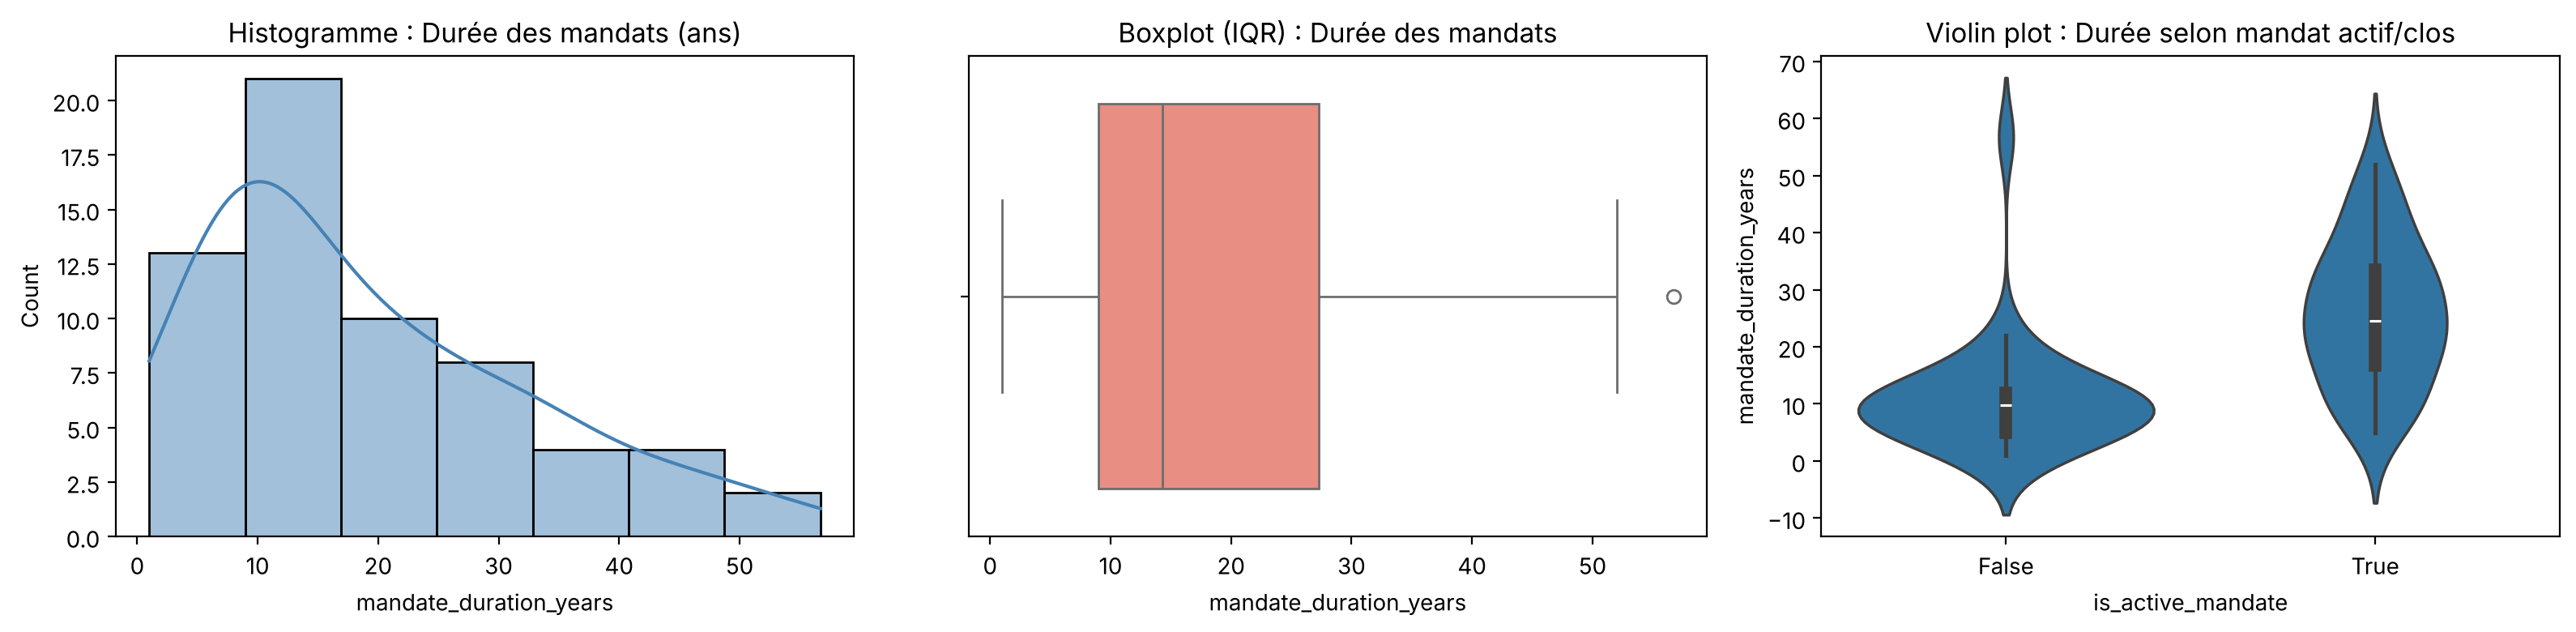

In [3]:
print(pa[pa["is_active_mandate"] & (pa["mandate_duration_years"] > 35)][
    ["office_holder_name", "recorded_birth_year", "age_at_end_or_2026", "office_title", "institution_name", "appointment_start", "mandate_duration_years"]
].sort_values("mandate_duration_years", ascending=False))

# Visualisation (histo + boxplot + violin plot)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(pa["mandate_duration_years"], kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Histogramme : Durée des mandats (ans)")
sns.boxplot(x=pa["mandate_duration_years"], ax=axes[1], color="salmon")
axes[1].set_title("Boxplot (IQR) : Durée des mandats")
sns.violinplot(x="is_active_mandate", y="mandate_duration_years", data=pa, ax=axes[2])
axes[2].set_title("Violin plot : Durée selon mandat actif/clos")
plt.tight_layout()
plt.show()

Plusieurs personnes occupent le même poste depuis plus de 35 ans, et certaines ont près de 80 ans ou plus. Pris un par un, ces mandats ne sont pas hors norme, mais ils sont nombreux à être très longs et toujours en cours.

### 2. Les demandes d'accès aux sites

`site_access_case_events` suit chaque demande d'accès à un site naturel, étape par étape. On regroupe les étapes pour avoir une ligne par demande (un « dossier »), puis on regarde qui fait des demandes, avec quel matériel et avec quel niveau de confidentialité.

In [4]:
# (1 ligne = 1 demande d'accès = 1 transaction)
sace_cases = sace.groupby("access_case_number").agg(
    site_code=("site_code", "first"),
    org_name=("requesting_organization_name", "first"),
    auth_agency=("authorizing_agency", "first"),
    purpose=("access_purpose", "first"),
    equipment=("equipment_category", "first"),
    conf_class=("confidentiality_class", "first"),
    start_time=("event_time", "min"),
    end_time=("event_time", "max"),
    n_events=("access_event_id", "count"),
    final_status=("new_status", "last")
).reset_index()

org_counts = sace_cases["org_name"].value_counts()
print(f"Top 5 des organisations demanderesses (sur {len(sace_cases)} dossiers)")
print(org_counts.head(5))

# Matrice de co-occurrences en pourcentage par ligne
cooc_eq_conf = pd.crosstab(sace_cases["equipment"], sace_cases["conf_class"], normalize="index") * 100
print("\nCo-occurrence Équipement vs Confidentialité (% par ligne)")
print(cooc_eq_conf.round(1))

Top 5 des organisations demanderesses (sur 60 dossiers)
org_name
Horizon Field Research Cooperative       18
Nordhaven Maritime Safety Agency          2
Valenne Laboratory Materials              2
Interregional Procurement Cooperative     2
Nordhaven Refrigeration Works             2
Name: count, dtype: int64

Co-occurrence Équipement vs Confidentialité (% par ligne)
conf_class                                      confidential  restricted  standard
equipment                                                                         
acoustic and camera equipment                           50.0        16.7      33.3
acoustic monitoring equipment                            8.3         8.3      83.3
camera equipment                                        25.0         0.0      75.0
maintenance tools                                       25.0         8.3      66.7
portable monitoring and cold-storage equipment          42.9        42.9      14.3
protective field equipment                       

- Une organisation fait beaucoup plus de demandes que les autres : Horizon Field Research Cooperative, avec 18 dossiers sur 60. Les autres en font 2 au plus.
- Le matériel « portable monitoring and cold-storage equipment » (suivi portable et stockage à froid) est presque toujours confidentiel ou restreint.

On vérifie avec une règle d'association qui demande ce matériel : si un dossier déclare du stockage à froid, est-il demandé par Horizon ?

In [5]:
N = len(sace_cases)
X = sace_cases["equipment"] == "portable monitoring and cold-storage equipment"
Y = sace_cases["org_name"] == "Horizon Field Research Cooperative"

supp_X = X.sum() / N
supp_Y = Y.sum() / N
supp_XY = (X & Y).sum() / N
conf_XY = supp_XY / supp_X
lift_XY = conf_XY / supp_Y

print("=== Règle d'association : {Cold-Storage Equipment} -> {Horizon Field Research Cooperative} ===")
print(f"  Support    : {(X & Y).sum()} dossiers sur {N} ({supp_XY*100:.1f}%)")
print(f"  Confiance  : {conf_XY*100:.1f}%")
print(f"  Lift       : {lift_XY:.2f}")

=== Règle d'association : {Cold-Storage Equipment} -> {Horizon Field Research Cooperative} ===
  Support    : 7 dossiers sur 60 (11.7%)
  Confiance  : 100.0%
  Lift       : 3.33


Tous les dossiers avec du stockage à froid viennent d'Horizon (confiance de 100 %, lift de 3,3).

### 3. Les heures et les étapes des dossiers

On regarde à quelle heure ont lieu les étapes des dossiers, pour Horizon et pour les autres.

In [6]:
sace["hour"] = sace["event_time"].dt.hour
print("Heure des événements selon l'activité (Toutes organisations vs Horizon)")
pd.crosstab([sace["requesting_organization_name"] == "Horizon Field Research Cooperative", sace["activity"]], sace["hour"])

Heure des événements selon l'activité (Toutes organisations vs Horizon)


hour                                                3   9   11  17  18
requesting_organization_name activity                                 
False                        access_completed        0   0  36   0   0
                             access_started          0   0   0  36   0
                             authorization_denied    0   6   0   0   0
                             authorization_granted   0  36   0   0   0
                             closure_recorded        0  42   0   0   0
                             request_submitted       0  42   0   0   0
                             technical_review        0  42   0   0   0
                             wildlife_review         0  28   0   0   0
True                         access_completed       18   0   0   0   0
                             access_started          0   0   0   0  18
                             authorization_denied    0   3   0   0   0
                             authorization_granted   0  18   0   0   0
                             closure_recorded        0   0  18   0   0
                             request_submitted       0  21   0   0   0
                             security_review         0  12   0   0   0
                             technical_review        0  18   0   0   0
                             wildlife_review         0  18   0   0   0

- Pour les autres organisations, l'entrée sur le site se fait à 17 h et la sortie à 11 h le lendemain.
- Pour Horizon, l'entrée se fait à 18 h et la sortie à 3 h du matin : les visites ont lieu la nuit.
- Horizon est la seule à passer par une étape de `security_review` (revue de sécurité).

### 4. Des personnes qui agissent à des dates impossibles

Dans `site_access`, chaque étape est validée par une personne. On compare ces dates avec ce que disent les autres fichiers sur ces personnes.

D'abord, les personnes déclarées décédées dans `public_appointments`.

In [7]:
deceased_info = pa[pa["departure_reason"] == "deceased"][["office_holder_name", "appointment_end"]].drop_duplicates()
sace_with_death = sace.merge(deceased_info, left_on="authorized_person_name", right_on="office_holder_name")
post_mortem_events = sace_with_death[sace_with_death["event_time"] > sace_with_death["appointment_end"]]
post_mortem_events[["access_event_id", "access_case_number", "site_code", "event_time", "activity", "authorized_person_name", "requesting_organization_name", "appointment_end"]]

,access_event_id,access_case_number,site_code,event_time,activity,authorized_person_name,requesting_organization_name,appointment_end
3,ACE-000172,ACC-2022-0023,KNT-JAK,2022-10-28 09:00:00,authorization_granted,Elira Vaun,Avelora Orchard Export Union,2021-09-18
4,ACE-000342,ACC-2022-0050,AVL-BVM,2022-08-10 09:00:00,technical_review,Elira Vaun,Civic Health Purchasing Network,2021-09-18
5,ACE-000370,ACC-2022-0054,AVL-FNM,2022-02-22 09:00:00,wildlife_review,Elira Vaun,Nordhaven Refrigeration Works,2021-09-18
6,ACE-000114,ACC-2024-0015,AVL-MAR,2024-05-10 09:00:00,wildlife_review,Elira Vaun,Horizon Field Research Cooperative,2021-09-18
7,ACE-000121,ACC-2024-0016,TMB-PEL,2024-07-15 09:00:00,request_submitted,Elira Vaun,Horizon Field Research Cooperative,2021-09-18
8,ACE-000227,ACC-2024-0032,KNT-TLQ,2024-08-12 09:00:00,request_submitted,Elira Vaun,Pelagos Marine Samples Laboratory,2021-09-18


Elira Vaun, déclarée décédée le 18 septembre 2021, valide 6 étapes de dossiers entre 2022 et 2024.

Si une personne décédée apparaît encore dans les dossiers, d'autres personnes ont peut-être aussi un âge impossible. Pour chaque personne qui valide des étapes de dossiers, on regarde son année de naissance dans `officer_filings`, et on garde celles nées avant 1930.

In [8]:
naissances = of.assign(nom=of["full_name"].str.replace("Dr. ", "", regex=False)).groupby("nom")["birth_year_est"].min()
historical_figures = naissances[(naissances < 1930) & naissances.index.isin(sace["authorized_person_name"])].index.tolist()
print("Personnes nées avant 1930 qui valident des étapes :", historical_figures, "\n")

print(sace[sace["authorized_person_name"].isin(historical_figures)].groupby("authorized_person_name").agg(
    nb_events=("access_event_id", "count"),
    first_seen=("event_time", "min"),
    last_seen=("event_time", "max"),
    orgs=("requesting_organization_name", lambda s: list(s.unique()))
))

Personnes nées avant 1930 qui valident des étapes : ['J. Varlan', 'Jonah Bell'] 

                        nb_events          first_seen           last_seen                                               orgs
authorized_person_name                                                                                                      
J. Varlan                       9 2015-02-25 09:00:00 2025-04-17 18:00:00  [Orison Facility Management, Blue Heron Monito...
Jonah Bell                      9 2018-04-10 09:00:00 2025-04-18 03:00:00  [Valenne Public Procurement Authority, Horizon...


J. Varlan (né en 1862) et Jonah Bell (né en 1900) valident des étapes de dossiers entre 2015 et 2025, donc à plus de 115 ans.

### 5. Des sociétés qui se succèdent

Leurs noms rappellent ceux de deux sociétés de `registered_entities` : Varlan Natural History Circle et Bell Conservation Survey. On regarde quand ces sociétés, et les autres, ont été créées, en les triant par date de création.

In [9]:
ent["founded_year"] = ent["registration_date"].dt.year
ent["dissolved_or_filing_year"] = ent["last_filing_date"].dt.year
ent.sort_values("founded_year")[
    ["registration_number", "legal_name", "registered_entity_type", "founded_year", "dissolved_or_filing_year", "current_status", "jurisdiction"]
].head(10)

,registration_number,legal_name,registered_entity_type,founded_year,dissolved_or_filing_year,current_status,jurisdiction
14,REG-NDH-01015,Vann Maritime Advisory,consulting_company,1838,1891,dissolved,nordhaven union
17,REG-KNT-01018,Varlan Natural History Circle,research_institute,1883,1920,dissolved,kintara republic
15,REG-VLN-01016,Warden Medical Ventures,investment_company,1894,1948,dissolved,valenne republic
18,REG-AVL-01019,Bell Conservation Survey,research_institute,1923,1966,dissolved,avelora federation
16,REG-NDH-01017,Vosmere Biotechnics,biotechnology_company,1951,1994,dissolved,nordhaven union
19,REG-VLN-01020,Marot Ecological Policy Office,consulting_company,1969,2006,dissolved,valenne republic
21,REG-NDH-01022,Nivren Maritime Logistics,logistics_company,1969,2025,active,nordhaven union
20,REG-VLN-01021,Solvane Energy Group,energy_company,1972,2025,active,valenne republic
23,REG-KNT-01024,Belen Agro-Industries,agricultural_company,1975,2025,active,kintara republic
22,REG-VLN-01023,Ardena Capital Union,financial_institution,1982,2025,active,valenne republic


Les sociétés dissoutes se suivent : chaque nouvelle société est créée 2 à 3 ans après la dissolution de la précédente, tous les 40 à 50 ans environ :
- Vann (1838–1891), puis Warden (1894–1948), puis Vosmere (1951–1994) ;
- Varlan (1883–1920), puis Bell (1923–1966), puis Marot (1969–2006).

### 6. Les sites visités et les dossiers réglementaires

On compare les sites visités par Horizon à ceux des autres organisations.

In [10]:
horizon_sites = set(sace_cases[sace_cases["org_name"] == "Horizon Field Research Cooperative"]["site_code"])
other_sites = set(sace_cases[sace_cases["org_name"] != "Horizon Field Research Cooperative"]["site_code"])
print(f"Sites visités par Horizon ({len(horizon_sites)}) : {sorted(horizon_sites)}")
print(f"Sites en commun avec les autres organisations : {len(horizon_sites & other_sites)}")

Sites visités par Horizon (8) : ['AVL-MAR', 'AVL-ORR', 'AVL-VEL', 'KNT-KES', 'KNT-LUM', 'KNT-SEN', 'TMB-NAC', 'TMB-PEL']
Sites en commun avec les autres organisations : 0


Horizon visite 8 sites, et aucune autre organisation n'y va.

`regulatory_case_events` suit des dossiers d'enquête, étape par étape. On reconstitue le parcours de chaque dossier (process mining) et on regarde ceux qui viennent de plaintes de la société civile (`civil society referral`).

In [11]:
rce_traces = rce.groupby("case_number").agg(
    source=("initiating_source", "first"),
    subject=("subject_name", "first"),
    site_code=("related_site_code", "first"),
    shipment=("related_shipment_number", "first"),
    trace=("activity", lambda s: " -> ".join(s)),
    final_outcome=("outcome", "last")
).reset_index()

csr_traces = rce_traces[rce_traces["source"] == "civil society referral"]
csr_traces[["case_number", "subject", "site_code", "shipment", "trace", "final_outcome"]]

,case_number,subject,site_code,shipment,trace,final_outcome
3,REG-2018-0001,Avelora Agricultural Resilience Agency,AVL-MAR,SHP-2018-00032,case_opened -> evidence_received -> triage_rev...,case closed
6,REG-2019-0002,Kintara Cave and Pollinator Authority,KNT-KES,SHP-2018-00007,case_opened -> evidence_received -> triage_rev...,case closed
13,REG-2020-0003,Meridian BioLogistics,TMB-PEL,SHP-2019-00009,case_opened -> evidence_received -> triage_rev...,case closed after review
17,REG-2021-0004,Avelora Agricultural Resilience Agency,AVL-MAR,SHP-2021-00028,case_opened -> evidence_received -> triage_rev...,case closed
18,REG-2021-0005,Meridian BioLogistics,AVL-MAR,SHP-2021-00028,case_opened -> evidence_received -> triage_rev...,case closed after review
20,REG-2022-0006,Tembara Biodiversity Service,TMB-NAC,SHP-2022-00018,case_opened -> evidence_received -> triage_rev...,case closed
21,REG-2022-0007,Avelora Agricultural Resilience Agency,AVL-VEL,SHP-2023-00071,case_opened -> evidence_received -> triage_rev...,action recorded
29,REG-2023-0008,Meridian BioLogistics,KNT-KES,SHP-2024-00007,case_opened -> evidence_received -> triage_rev...,case closed after review
35,REG-2024-0009,Meridian BioLogistics,AVL-MAR,SHP-2024-00011,case_opened -> evidence_received -> triage_rev...,case closed after review
38,REG-2025-0010,Kintara Cave and Pollinator Authority,KNT-SEN,SHP-2025-00005,case_opened -> evidence_received -> triage_rev...,action recorded


- Les 10 plaintes de la société civile portent toutes sur des sites visités par Horizon, et citent un numéro de livraison (`SHP-…`).
- 4 plaintes visent Meridian BioLogistics. Ce sont les seules qui passent par l'étape `referral_recorded` et se terminent par « case closed after review », sans décision.

La matrice de transition montre quelle étape suit quelle autre, pour tous les dossiers.

In [12]:
rce["next_activity"] = rce.groupby("case_number")["activity"].shift(-1)
transitions = pd.crosstab(rce["activity"], rce["next_activity"].fillna("END"))
transitions

next_activity,END,case_closed,evidence_received,finding_issued,inspection_completed,inspection_scheduled,referral_recorded,technical_review,triage_review
activity,,,,,,,,,
case_closed,40,0,0,0,0,0,0,0,0
case_opened,0,0,40,0,0,0,0,0,0
evidence_received,0,0,0,0,0,0,0,0,40
finding_issued,0,11,0,0,0,0,0,0,0
inspection_completed,0,10,0,6,0,0,1,0,0
inspection_scheduled,0,0,0,0,17,0,0,0,0
referral_recorded,0,4,0,0,0,0,0,0,0
technical_review,0,15,0,5,0,0,3,0,0
triage_review,0,0,0,0,0,17,0,23,0


L'étape `referral_recorded` n'apparaît que 4 fois sur 40 dossiers : ce sont les 4 plaintes contre Meridian.

### 7. Réseau des personnes et des organisations

On construit un graphe qui relie chaque personne aux organisations dont elle valide les dossiers, et on calcule la centralité de chaque nœud. La betweenness mesure combien un nœud sert de pont entre les autres.

In [13]:
G = nx.Graph()
for _, row in sace.dropna(subset=["authorized_person_name", "requesting_organization_name"]).iterrows():
    person = row["authorized_person_name"]
    org = row["requesting_organization_name"]
    G.add_node(person, bipartite="person")
    G.add_node(org, bipartite="org")
    if G.has_edge(person, org):
        G[person][org]["weight"] += 1
    else:
        G.add_edge(person, org, weight=1)

bet_cent = nx.betweenness_centrality(G, weight="weight")
clos_cent = nx.closeness_centrality(G)

pd.DataFrame({
    "node": list(G.nodes()),
    "type": [G.nodes[n]["bipartite"] for n in G.nodes()],
    "degree": [G.degree(n) for n in G.nodes()],
    "betweenness": [bet_cent[n] for n in G.nodes()],
    "closeness": [clos_cent[n] for n in G.nodes()]
}).sort_values("betweenness", ascending=False).head(10).round(3)

,node,type,degree,betweenness,closeness
70,Civic Health Purchasing Network,org,14,0.109,0.425
17,Farah Ferran,person,12,0.070,0.478
20,Valenne Laboratory Materials,org,11,0.056,0.412
67,Kintara Field Equipment Cooperative,org,11,0.055,0.421
62,Auric Medical Supplies,org,11,0.055,0.407
43,Interregional Procurement Cooperative,org,10,0.053,0.403
51,Valenne Public Procurement Authority,org,12,0.052,0.430
1,Nordhaven Maritime Safety Agency,org,12,0.051,0.399
37,Horizon Field Research Cooperative,org,46,0.049,0.706
28,Mara Venn,person,8,0.040,0.456


- Horizon est reliée à beaucoup plus de personnes que les autres (degré de 46) et c'est la plus proche de tout le réseau.
- Les ponts entre les groupes sont surtout des organismes d'achat (Civic Health Purchasing Network) et quelques personnes, comme Farah Ferran et Mara Venn.

### 8. Les documents publics et d'enquête

`public_and_investigative_documents` contient 40 documents. On cherche les thèmes avec TF-IDF et une LSA, qui regroupe les mots qui apparaissent souvent ensemble.

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), max_features=500)
tfidf_matrix = vectorizer.fit_transform(paid["text"])
feature_names = vectorizer.get_feature_names_out()

lsa = TruncatedSVD(n_components=3, random_state=42)
lsa.fit(tfidf_matrix)
for topic_idx, comp in enumerate(lsa.components_):
    print(f"Topic {topic_idx + 1} : {', '.join(feature_names[i] for i in comp.argsort()[:-11:-1])}")

# Termes TF-IDF les plus fréquents dans les documents restreints
restricted_mask = (paid["public_or_restricted"] == "restricted").to_numpy()
restricted_mean_tfidf = np.asarray(tfidf_matrix[restricted_mask].mean(axis=0)).ravel()
print("\nMots-clés des documents 'restricted' :", [feature_names[i] for i in restricted_mean_tfidf.argsort()[:-16:-1]])

Topic 1 : records, document, justice, accountability, climate, verification, ordinary, hidden, unresolved, evidence
Topic 2 : public, mandate, body, issuing, issuing body, matter, confidentiality, options, documented mandate, matter concerns
Topic 3 : notes, provenance, item, recorded, archival, identity, catalog, later, travel, names

Mots-clés des documents 'restricted' : ['records', 'public', 'ordinary', 'evidence', 'record', 'justice', 'restricted', 'notes', 'biological', 'clinical', 'external', 'historical', 'document', 'addresses', 'does']


- Trois thèmes ressortent : la justice environnementale et la responsabilité, le contrôle de l'information et les mandats publics, et les archives et identités.
- Les documents restreints parlent davantage de « biological », « clinical » et « historical ».

On liste les documents restreints pour les lire.

In [15]:
paid[paid["public_or_restricted"] == "restricted"][["document_id", "document_date", "author_organization", "title"]]

,document_id,document_date,author_organization,title
0,PUB-510045,2022-07-08,Orison Medical Audit Board,Restricted Review of Recurrent Executive Healt...
4,PUB-510044,2025-02-21,Lantern Investigative Bureau,Jacob Vale Identity-Continuity Lead
5,PUB-510079,2025-04-09,Lantern Investigative Bureau,Message Concerning Collected Eonycteris
6,PUB-510063,2025-05-16,Lantern Investigative Bureau,Restricted Classification and External-Transfe...
12,PUB-510017,2023-04-16,Avelora Council of State,Public Statement 87
14,PUB-510049,2021-02-03,Kintara Cave and Pollinator Authority,Confidential Review Briefing 89
19,PUB-510111,2020-03-11,Lantern Investigative Bureau,Campaign Statement 94
23,PUB-510052,2024-11-12,Asterion Clinical Institute,Open Letter on Public Records 98
26,PUB-510066,2025-02-06,Pollinator Justice Network,Witness Testimony 101
32,PUB-510072,2019-08-21,Lantern Investigative Bureau,Research Summary 107


Un titre parle de santé des dirigeants : PUB-510045, « Restricted Review of Recurrent Executive Health Interventions ». Un autre parle d'*Eonycteris*, l'espèce de chauve-souris citée dans le rapport de KNT-KES en écologie : on le garde pour les croisements. On lit PUB-510045.

In [16]:
doc_pub45 = paid[paid["document_id"] == "PUB-510045"].iloc[0]
print(f"=== {doc_pub45['document_id']} : {doc_pub45['title']} ===")
print(f"Auteur : {doc_pub45['author_name']} ({doc_pub45['author_organization']}) - {doc_pub45['document_date'].date()}\n")
print(doc_pub45["text"])

=== PUB-510045 : Restricted Review of Recurrent Executive Health Interventions ===
Auteur : Dr. Lysa Quen (Orison Medical Audit Board) - 2022-07-08

PURPOSE
This restricted briefing summarizes a small set of senior office-holders and corporate leaders who have received recurrent confidential health interventions through overlapping providers.

EVIDENCE REVIEWED
Appointment archives, professional licences, facility records, encounter dates, and restricted procedure summaries were compared. Eight individuals show repeated specialist attendance over several years. Their public roles differ, and no common diagnosis is recorded in the accessible files. The same limited group of clinicians and facilities appears more often than expected from the individuals' home regions and ordinary referral pathways. Several interventions occur shortly before a return to demanding public duties.

INTERPRETATION
The recurrence and provider overlap are supported findings. The purpose of the interventions is 

Le document décrit 8 hauts responsables qui reçoivent des soins confidentiels répétés, chez les mêmes médecins et établissements. Il propose de comparer leur âge biologique à leur âge réel, et de vérifier si les mêmes prestataires apparaissent dans la logistique.

## Partie Dali

### 1. Anciennetés et durées hors norme

On cherche les valeurs hors norme dans l'ancienneté des licences professionnelles, la durée des mandats dans les sociétés et l'âge à la nomination.

=== license_age_years (n=53) ===
  Moyenne : 29.44 | Écart-type : 26.40
  Médiane : 23.50 | Min : -0.50 | Max : 139.50 | Q1 : 16.50 | Q3 : 31.50 | IQR : 15.00
      name_clean                          profession license_issue_date primary_facility_license  license_age_years  z_score
6      J. Varlan               research professional         1886-07-01              FAC-AVL-301              139.5     4.17
0    Emil Warden                           physician         1895-07-01              FAC-VLN-101              130.5     3.83
7     Jonah Bell               research professional         1924-07-01              FAC-AVL-301              101.5     2.73
12    Elira Vaun  public administration professional         1965-07-01                      NaN               60.5     1.18
8   Julien Marot          environmental professional         1970-07-01              FAC-AVL-301               55.5     0.99

=== mandate_duration_years (n=135) ===
  Moyenne : 18.34 | Écart-type : 13.02
  Médiane : 

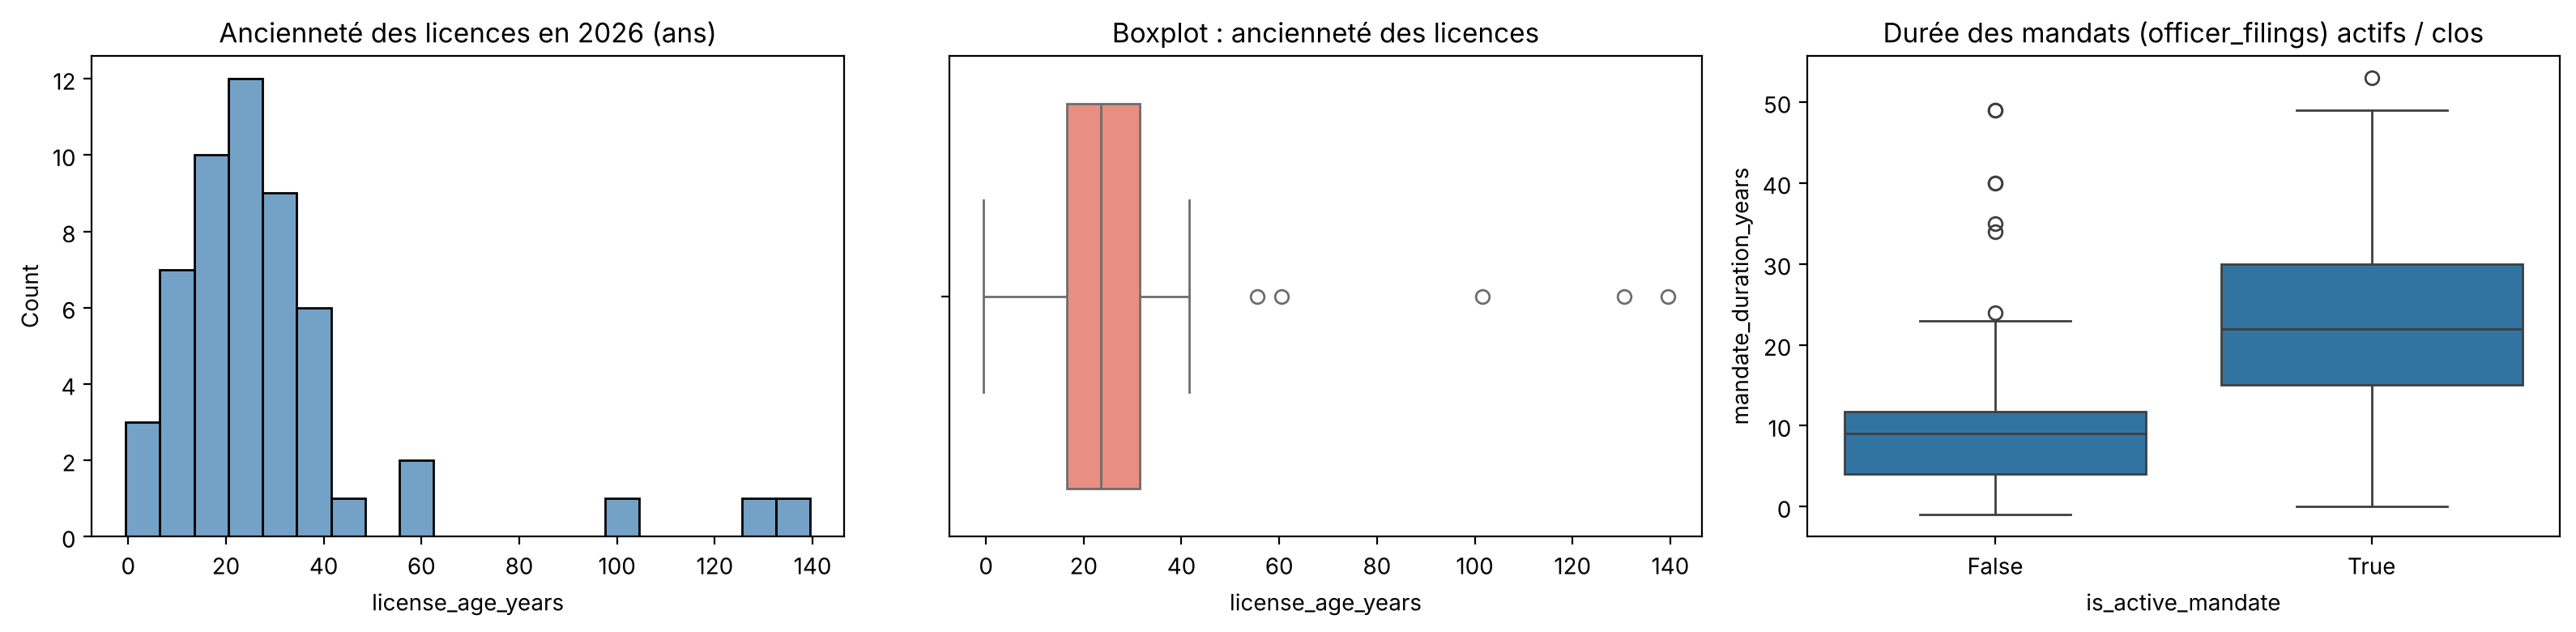

In [17]:
def stats_and_outliers(df, col, cols_affichees):
    s = df[col].dropna().astype(float)
    mean, std = s.mean(), s.std()
    med, q1, q3 = s.median(), s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1

    print(f"=== {col} (n={len(s)}) ===")
    print(f"  Moyenne : {mean:.2f} | Écart-type : {std:.2f}")
    print(f"  Médiane : {med:.2f} | Min : {s.min():.2f} | Max : {s.max():.2f} | Q1 : {q1:.2f} | Q3 : {q3:.2f} | IQR : {iqr:.2f}")

    iqr_mask = (df[col] < (q1 - 1.5 * iqr)) | (df[col] > (q3 + 1.5 * iqr))
    z_score = (df[col] - mean) / std
    outliers = df[iqr_mask | (z_score.abs() > 2.5)].copy()
    outliers["z_score"] = z_score.round(2)
    return outliers[cols_affichees + [col, "z_score"]].sort_values(col, ascending=False)

print(stats_and_outliers(lp, "license_age_years", ["name_clean", "profession", "license_issue_date", "primary_facility_license"]))
print()
print(stats_and_outliers(of, "mandate_duration_years", ["full_name", "registration_number", "role_title", "appointment_date", "cessation_date"]))
print()
print(stats_and_outliers(of, "age_at_appointment", ["full_name", "birth_year_or_age_band", "role_title", "appointment_date"]))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(lp["license_age_years"], bins=20, ax=axes[0], color="steelblue")
axes[0].set_title("Ancienneté des licences en 2026 (ans)")
sns.boxplot(x=lp["license_age_years"], ax=axes[1], color="salmon")
axes[1].set_title("Boxplot : ancienneté des licences")
sns.boxplot(x="is_active_mandate", y="mandate_duration_years", data=of, ax=axes[2])
axes[2].set_title("Durée des mandats (officer_filings) actifs / clos")
plt.tight_layout()
plt.show()

- Certaines licences professionnelles ont plus de 100 ans et sont toujours actives : J. Varlan (1886), Emil Warden (1895), Jonah Bell (1924).
- Les mandats les plus longs dans les sociétés dépassent 45 ans.

### 2. Nominations et fondateurs

On relie chaque nomination à la société concernée pour comparer la date de nomination à la date de création de la société.

In [18]:
of_ent = of.merge(ent[["registration_number", "legal_name", "registration_date", "current_status"]], on="registration_number", how="left")
of_ent["avant_creation"] = of_ent["appointment_date"] < of_ent["registration_date"]
print("Nominations avant la date d'enregistrement de la société :", of_ent["avant_creation"].sum())

print("\nDirigeants des sociétés dissoutes")
of_ent[of_ent["current_status"] == "dissolved"][["full_name", "birth_year_or_age_band", "legal_name", "registration_date", "appointment_date", "cessation_date"]].sort_values("appointment_date")

Nominations avant la date d'enregistrement de la société : 49

Dirigeants des sociétés dissoutes


,full_name,birth_year_or_age_band,legal_name,registration_date,appointment_date,cessation_date
42,Edward Vann,1815,Vann Maritime Advisory,1838-01-15,1840-01-01,1888-12-31
23,J. Varlan,1862,Varlan Natural History Circle,1883-01-15,1885-01-01,1918-12-31
113,Emil Warden,1871,Warden Medical Ventures,1894-01-15,1895-01-01,1943-12-31
22,Jonah Bell,1900,Bell Conservation Survey,1923-01-15,1924-01-01,1963-12-31
43,Adrian Vosmere,1920–1929,Vosmere Biotechnics,1951-01-15,1952-01-01,1991-12-31
114,Julien Marot,1940–1949,Marot Ecological Policy Office,1969-01-15,1970-01-01,2004-12-31


- 49 nominations ont lieu avant la date d'enregistrement de la société : ces dates d'enregistrement ne sont pas fiables, ou certaines personnes étaient nommées avant que la société existe officiellement.
- Chaque société dissoute a un dirigeant fondateur, nommé entre 1840 et 1970.

On regarde si ces fondateurs ont une licence professionnelle et s'ils apparaissent sur le terrain.

In [19]:
fondateurs = of_ent[of_ent["current_status"] == "dissolved"][["full_name", "birth_year_or_age_band", "legal_name", "cessation_date"]]
fondateurs = fondateurs.merge(lp[["name_clean", "profession", "license_issue_date", "primary_facility_license"]], left_on="full_name", right_on="name_clean", how="left")
fondateurs = fondateurs.merge(lf[["facility_license_number", "facility_name"]], left_on="primary_facility_license", right_on="facility_license_number", how="left")

terrain = sace.groupby("authorized_person_name").agg(nb_events=("access_event_id", "count"), first_seen=("event_time", "min"), last_seen=("event_time", "max"))
fondateurs = fondateurs.merge(terrain, left_on="full_name", right_index=True, how="left")
fondateurs[["full_name", "birth_year_or_age_band", "legal_name", "cessation_date", "license_issue_date", "facility_name", "nb_events", "last_seen"]]

,full_name,birth_year_or_age_band,legal_name,cessation_date,license_issue_date,facility_name,nb_events,last_seen
0,Jonah Bell,1900,Bell Conservation Survey,1963-12-31,1924-07-01,Threshold Earth Avelora Laboratory,9.0,2025-04-18 03:00:00
1,J. Varlan,1862,Varlan Natural History Circle,1918-12-31,1886-07-01,Threshold Earth Avelora Laboratory,9.0,2025-04-17 18:00:00
2,Edward Vann,1815,Vann Maritime Advisory,1888-12-31,NaT,NaN,NaN,NaT
3,Adrian Vosmere,1920–1929,Vosmere Biotechnics,1991-12-31,NaT,NaN,NaN,NaT
4,Emil Warden,1871,Warden Medical Ventures,1943-12-31,1895-07-01,Asterion Central Clinical Campus,NaN,NaT
5,Julien Marot,1940–1949,Marot Ecological Policy Office,2004-12-31,1970-07-01,Threshold Earth Avelora Laboratory,5.0,2024-08-27 11:00:00


Trois fondateurs (Jonah Bell, J. Varlan, Julien Marot) ont une licence toujours active dans le même laboratoire, et valident encore des dossiers d'accès récents.

On compte ensuite dans combien de fichiers apparaît chaque professionnel.

In [20]:
sources = {
    "officer_filings": set(of["full_name"]),
    "public_appointments": set(pa["office_holder_name"]),
    "site_access": set(sace["authorized_person_name"].dropna()),
    "memos (auteurs)": set(im["author_name"].str.replace("Dr. ", "", regex=False)),
}
presence = pd.DataFrame({src: lp["name_clean"].isin(noms) for src, noms in sources.items()})
presence.index = lp["name_clean"]
presence["nb_fichiers"] = presence.sum(axis=1)
print("Personnes présentes dans au moins 3 fichiers :")
print(presence[presence["nb_fichiers"] >= 3].sort_values("nb_fichiers", ascending=False))

print()
print(pa[pa["office_holder_name"] == "Elira Vaun"][["office_holder_name", "office_title", "appointment_start", "appointment_end", "departure_reason"]])
print(lp[lp["name_clean"] == "Elira Vaun"][["license_number", "profession", "license_issue_date", "license_status"]])

Personnes présentes dans au moins 3 fichiers :
              officer_filings  public_appointments  site_access  memos (auteurs)  nb_fichiers
name_clean                                                                                   
Tomas Pell               True                False         True             True            3
Liora Maren              True                 True         True            False            3
Calen Uren               True                 True         True            False            3
Bela Ferran              True                False         True             True            3
Liora Corda              True                 True         True            False            3
Petra Grell              True                 True         True            False            3
Doran Maren              True                 True         True            False            3
Jalen Quorin             True                 True         True            False            3
Marek Kerin  

Elira Vaun est déclarée décédée en 2021, mais sa licence est toujours active.

### 3. Réseau des sociétés

On regarde quand une personne passe d'une société à une autre. Chaque passage crée un lien entre deux sociétés.

27 personnes passent d'une société à une autre
                                    sortants  entrants  betweenness
Whitehaven Strategic Holdings              5         1        0.036
Ardena Capital Union                       4         2        0.036
Valenne Industrial Futures Council         4         2        0.036
Meridian–Asterion Foundation               4         0        0.000
Threshold Earth Observatory                4         0        0.000
Solvane Energy Group                       3         3        0.036
Helix Legal and Compliance                 2         2        0.000
Meridian BioLogistics                      1         3        0.000
Northstar Cold Chain Services              1         5        0.009
Nivren Maritime Logistics                  1         5        0.027
Horizon Field Research Cooperative         1         3        0.000
Common Ground Climate Forum                0         4        0.000


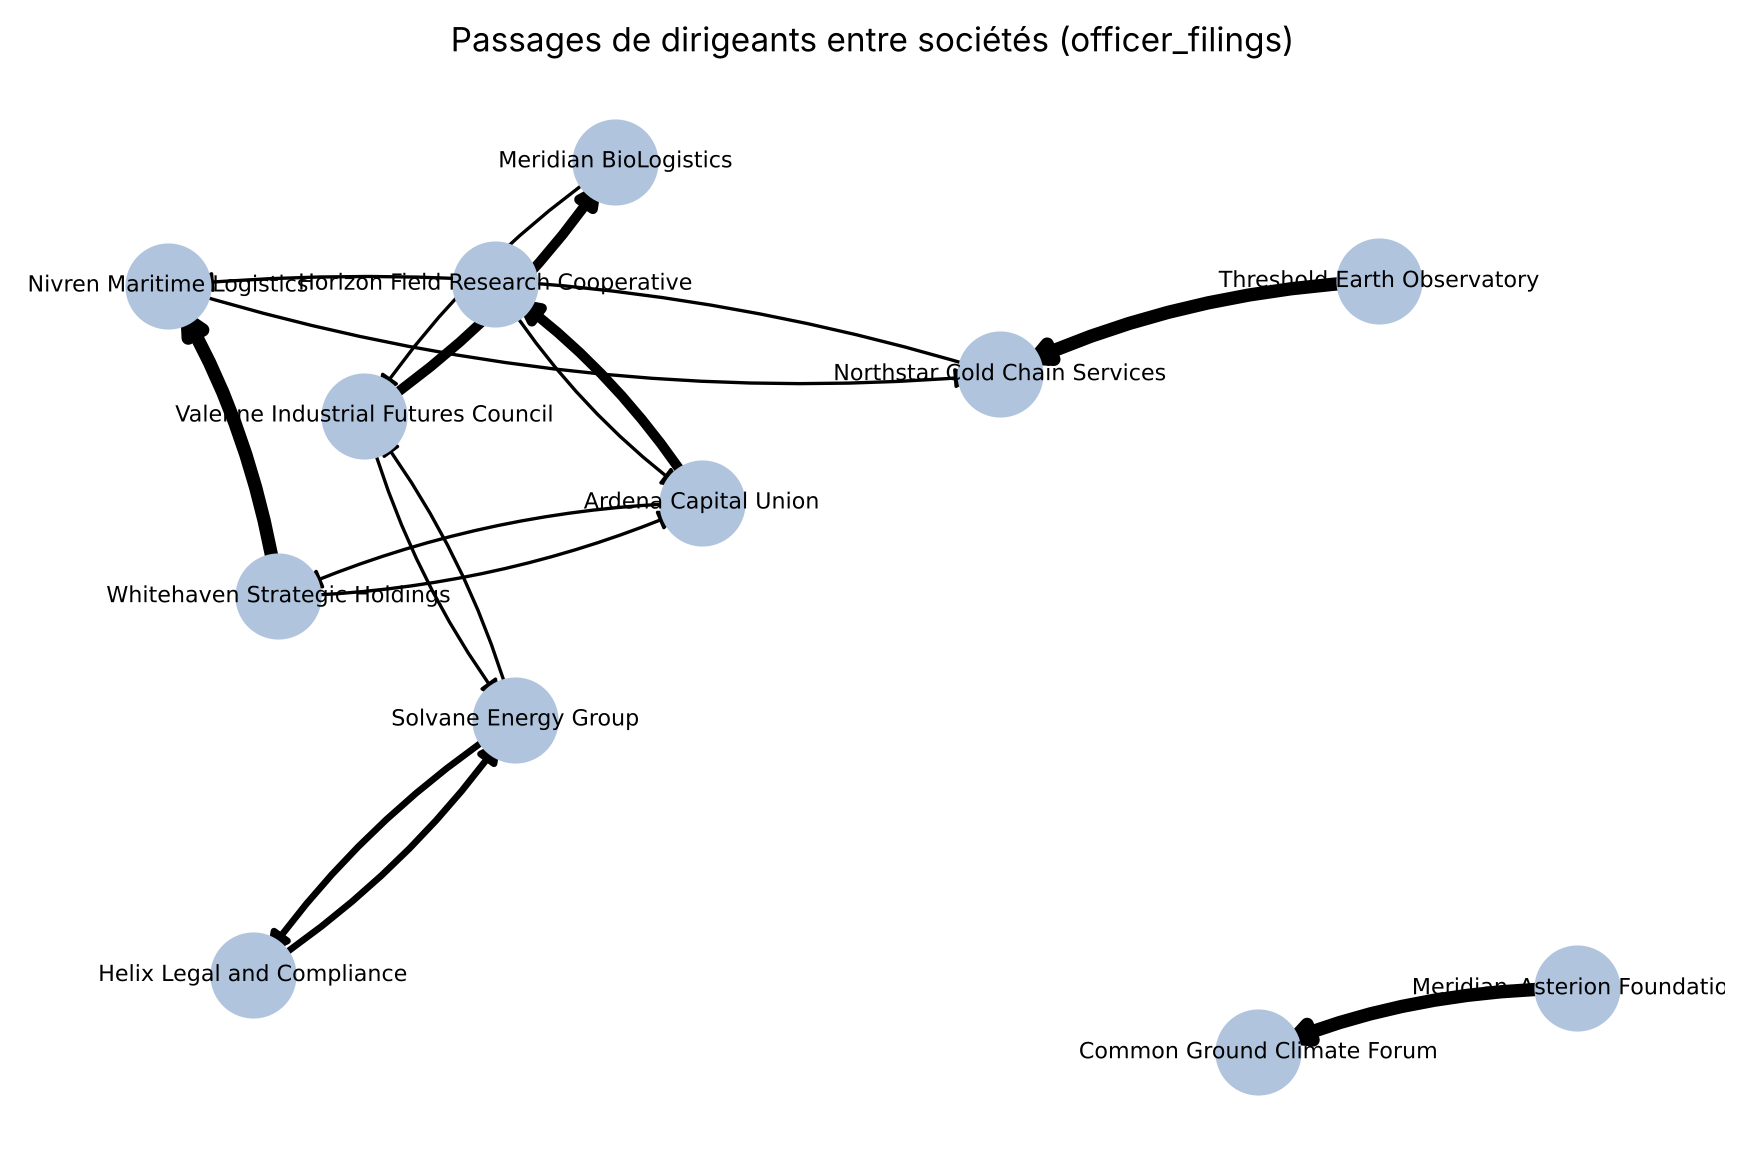

In [21]:
of_ent = of_ent.sort_values(["full_name", "appointment_date"])
of_ent["societe_suivante"] = of_ent.groupby("full_name")["legal_name"].shift(-1)
transitions = of_ent.dropna(subset=["societe_suivante"])
transitions = transitions[transitions["legal_name"] != transitions["societe_suivante"]]
print(f"{transitions['full_name'].nunique()} personnes passent d'une société à une autre")

G = nx.DiGraph()
for _, row in transitions.iterrows():
    a, b = row["legal_name"], row["societe_suivante"]
    if G.has_edge(a, b):
        G[a][b]["weight"] += 1
    else:
        G.add_edge(a, b, weight=1)

centralite = pd.DataFrame({
    "sortants": dict(G.out_degree(weight="weight")),
    "entrants": dict(G.in_degree(weight="weight")),
    "betweenness": nx.betweenness_centrality(G),
}).sort_values("sortants", ascending=False)
print(centralite.round(3))

plt.figure(figsize=(11, 7))
pos = nx.spring_layout(G, seed=0, k=1.2)
nx.draw_networkx_nodes(G, pos, node_color="lightsteelblue", node_size=900)
nx.draw_networkx_labels(G, pos, font_size=8)
nx.draw_networkx_edges(G, pos, width=[G[u][v]["weight"] * 1.2 for u, v in G.edges()], arrows=True, arrowsize=15, connectionstyle="arc3,rad=0.1")
plt.title("Passages de dirigeants entre sociétés (officer_filings)")
plt.axis("off")
plt.show()

On cherche ensuite des groupes de sociétés très liées entre elles avec l'algorithme de Louvain. La modularité dit si les groupes sont nets (proche de 1) ou non (proche de 0).

In [22]:
G_nd = nx.Graph()
for u, v, d in G.edges(data=True):
    if G_nd.has_edge(u, v):
        G_nd[u][v]["weight"] += d["weight"]
    else:
        G_nd.add_edge(u, v, weight=d["weight"])

communautes = nx.community.louvain_communities(G_nd, weight="weight", seed=0)
modularite = nx.community.modularity(G_nd, communautes, weight="weight")
print(f"{len(communautes)} communautés, modularité = {modularite:.3f}")
for k, com in enumerate(communautes):
    print(f"  Communauté {k + 1} : {sorted(com)}")

5 communautés, modularité = 0.642
  Communauté 1 : ['Ardena Capital Union', 'Horizon Field Research Cooperative']
  Communauté 2 : ['Nivren Maritime Logistics', 'Whitehaven Strategic Holdings']
  Communauté 3 : ['Helix Legal and Compliance', 'Meridian BioLogistics', 'Solvane Energy Group', 'Valenne Industrial Futures Council']
  Communauté 4 : ['Common Ground Climate Forum', 'Meridian–Asterion Foundation']
  Communauté 5 : ['Northstar Cold Chain Services', 'Threshold Earth Observatory']


Les sociétés forment 5 petits groupes assez nets. Meridian BioLogistics est dans un groupe avec Solvane Energy Group, Helix Legal and Compliance et le Valenne Industrial Futures Council.

### 4. Profils des dirigeants

On décrit chaque dirigeant par quelques chiffres : année de naissance, âge à la première nomination, années de mandat cumulées, nombre de mandats et de sociétés, mandat en cours ou non, nombre d'étapes validées sur le terrain, ancienneté de licence. Il n'y a que 104 personnes : les résultats sont à lire avec prudence.

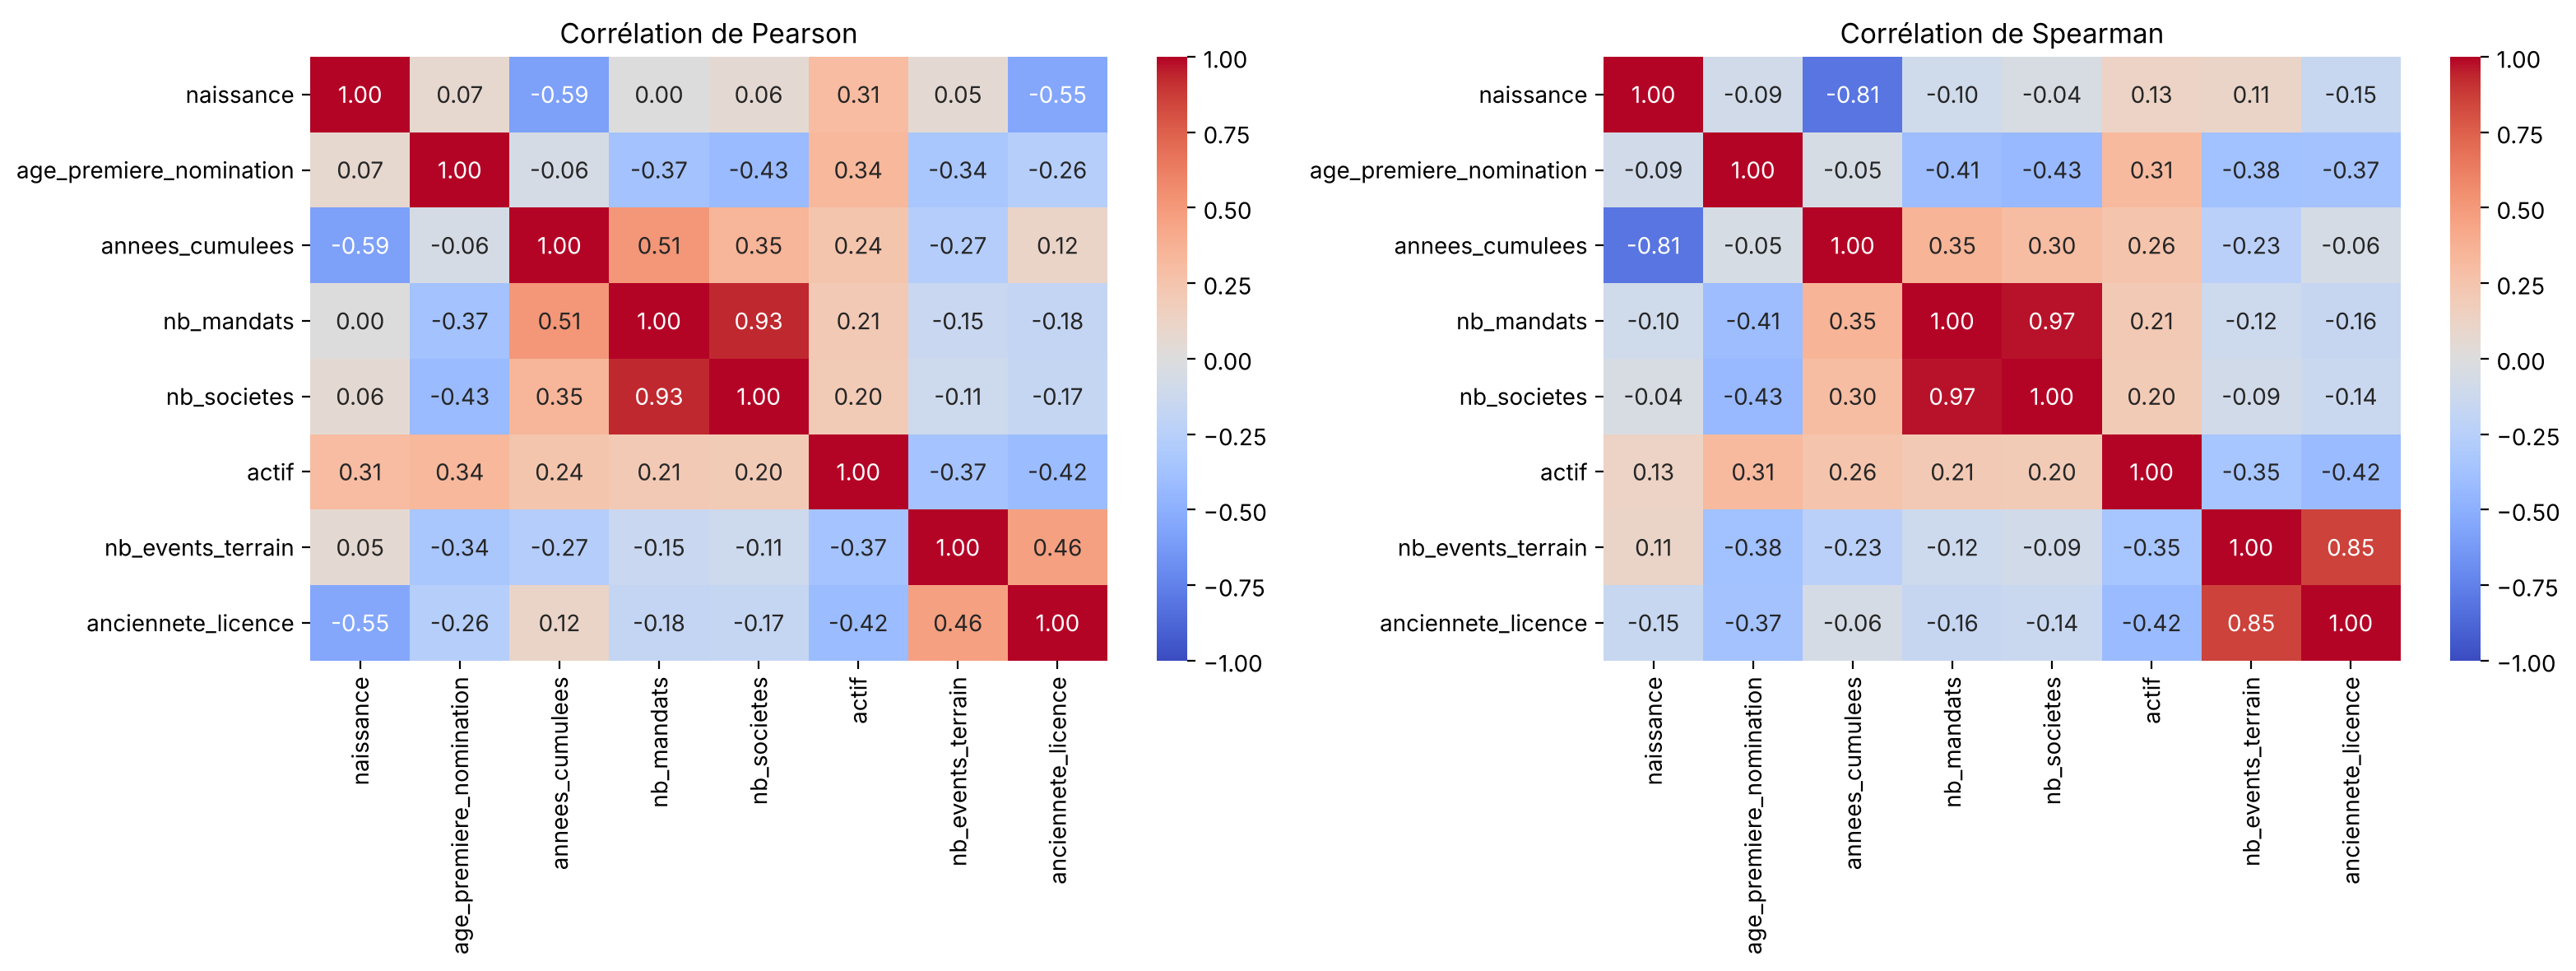

In [23]:
personnes = of_ent.groupby("full_name").agg(
    naissance=("birth_year_est", "first"),
    premiere_nomination=("appointment_date", "min"),
    annees_cumulees=("mandate_duration_years", lambda s: s.clip(lower=0).sum()),
    nb_mandats=("filing_id", "count"),
    nb_societes=("registration_number", "nunique"),
    actif=("is_active_mandate", "max"),
)
personnes["age_premiere_nomination"] = personnes["premiere_nomination"].dt.year - personnes["naissance"]
personnes["nb_events_terrain"] = personnes.index.map(sace["authorized_person_name"].value_counts()).fillna(0)
personnes["anciennete_licence"] = personnes.index.map(lp.set_index("name_clean")["license_age_years"]).fillna(0)
personnes["actif"] = personnes["actif"].astype(int)

variables = ["naissance", "age_premiere_nomination", "annees_cumulees", "nb_mandats", "nb_societes", "actif", "nb_events_terrain", "anciennete_licence"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, methode in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(personnes[variables].corr(method=methode), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
    ax.set_title(f"Corrélation de {methode.capitalize()}")
plt.tight_layout()
plt.show()

On résume ces chiffres avec une ACP, puis on regroupe les dirigeants avec une classification hiérarchique (CAH).

In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, fcluster

X = StandardScaler().fit_transform(personnes[variables])
acp = PCA()
coords = acp.fit_transform(X)
print("Variance expliquée (%) :", (acp.explained_variance_ratio_ * 100).round(1))
personnes["PC1"], personnes["PC2"] = coords[:, 0], coords[:, 1]

Z = linkage(X, method="ward")
personnes["cah"] = fcluster(Z, t=4, criterion="maxclust")
print(personnes.groupby("cah")[variables].mean().round(1))
print(personnes["cah"].value_counts().sort_index())

Variance expliquée (%) : [32.1 28.1 19.8  8.5  4.9  4.1  1.9  0.5]
     naissance  age_premiere_nomination  annees_cumulees  nb_mandats  nb_societes  actif  nb_events_terrain  anciennete_licence
cah                                                                                                                            
1       1970.6                     24.3             32.7         2.1          2.0    0.9                2.2                 5.1
2       1974.3                     30.5             21.5         1.0          1.0    1.0                0.0                -0.0
3       1862.0                     24.0             43.0         1.0          1.0    0.0                4.5                92.9
4       1971.9                     26.0             17.0         1.0          1.0    0.4                7.5                22.0
cah
1    27
2    41
3     4
4    32
Name: count, dtype: int64


- Les deux premiers axes de l'ACP résument 60 % de l'information.
- La CAH sépare un petit groupe de personnes nées au XIXe siècle, avec des licences très anciennes, du reste des dirigeants.

### 5. Dirigeants atypiques : DBSCAN et LOF

Pour DBSCAN, on choisit `eps` en regardant la distance de chaque personne à son 5e voisin : `eps` doit se trouver là où cette distance commence à monter fortement. Pour le LOF, on teste plusieurs nombres de voisins.

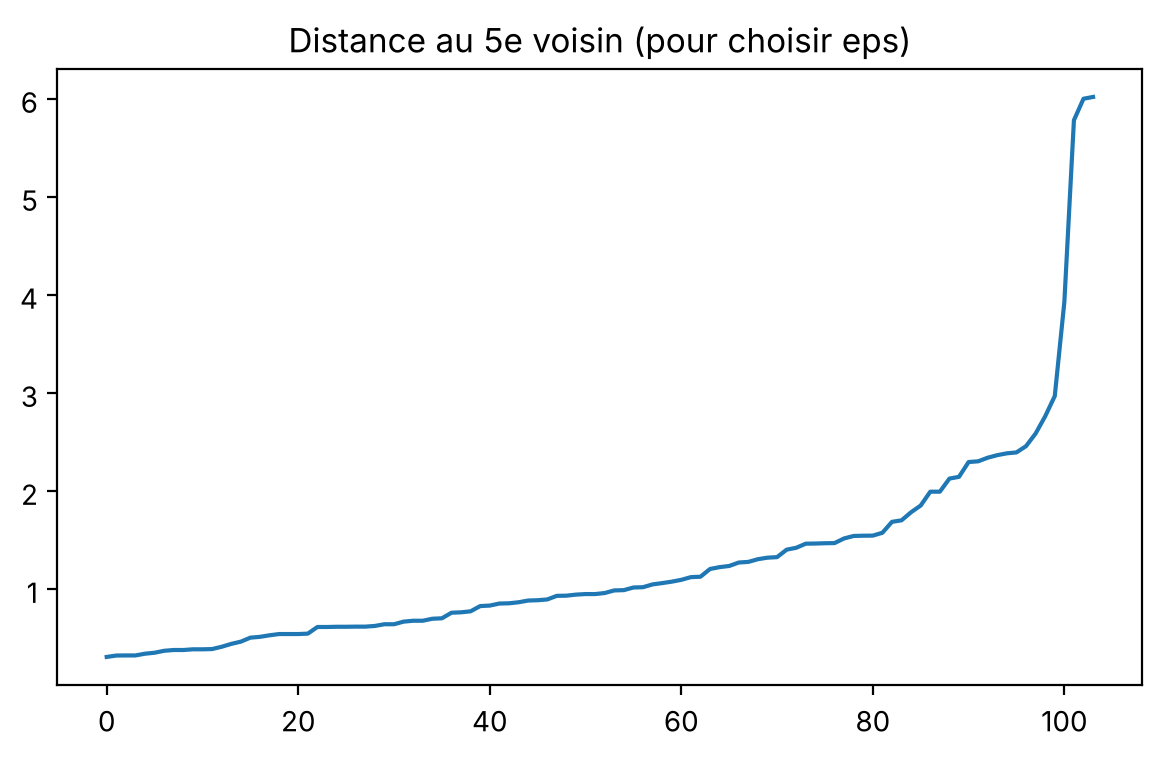

eps=1.0 : 4 cluster(s), 33 points de bruit
eps=1.5 : 4 cluster(s), 18 points de bruit
eps=2.0 : 3 cluster(s), 12 points de bruit

Atypiques pour DBSCAN et le LOF à la fois : 9


,naissance,annees_cumulees,nb_societes,nb_events_terrain,anciennete_licence,lof_score
full_name,,,,,,
Edward Vann,1815.0,49.0,1,0.0,0.0,2.86
J. Varlan,1862.0,34.0,1,9.0,139.5,2.13
Emil Warden,1871.0,49.0,1,0.0,130.5,2.13
Adrian Vosmere,1924.5,40.0,1,0.0,0.0,2.03
Elian Cevan,1992.0,0.0,1,0.0,0.0,1.88
Gita Aren,1964.5,23.0,1,0.0,0.0,1.75
Rayan Belen,1952.0,55.0,1,0.0,0.0,1.71
Jonah Bell,1900.0,40.0,1,9.0,101.5,1.67
Xara Aren,1987.0,10.0,1,0.0,0.0,1.57


In [25]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors

dist, _ = NearestNeighbors(n_neighbors=5).fit(X).kneighbors(X)
plt.figure(figsize=(7, 4))
plt.plot(np.sort(dist[:, -1]))
plt.title("Distance au 5e voisin (pour choisir eps)")
plt.show()

for eps in [1.0, 1.5, 2.0]:
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
    print(f"eps={eps} : {len(set(lab)) - (1 if -1 in lab else 0)} cluster(s), {(lab == -1).sum()} points de bruit")
personnes["dbscan"] = DBSCAN(eps=1.5, min_samples=5).fit_predict(X)

lof = LocalOutlierFactor(n_neighbors=20)
personnes["lof"] = lof.fit_predict(X)
personnes["lof_score"] = -lof.negative_outlier_factor_

outliers = personnes[(personnes["dbscan"] == -1) & (personnes["lof"] == -1)]
print(f"\nAtypiques pour DBSCAN et le LOF à la fois : {len(outliers)}")
outliers.sort_values("lof_score", ascending=False)[["naissance", "annees_cumulees", "nb_societes", "nb_events_terrain", "anciennete_licence", "lof_score"]].round(2)

Sur les 9 dirigeants atypiques pour les deux méthodes, 5 sont nés au XIXe siècle ou au début du XXe. Les autres ont des durées de mandat inhabituelles, très courtes ou très longues.

### 6. Les mémos

On relie les mémos aux dossiers d'accès et aux dossiers réglementaires qu'ils citent, puis on cherche les mots qui distinguent les mémos selon leur niveau de visibilité.

In [26]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), max_features=500, min_df=2)
tfidf = vectorizer.fit_transform(im["text"])
mots = vectorizer.get_feature_names_out()

for niveau in ["internal", "confidential", "restricted"]:
    mask = (im["visibility_level"] == niveau).to_numpy()
    moy = np.asarray(tfidf[mask].mean(axis=0)).ravel()
    print(f"{niveau:<13}: {', '.join(mots[i] for i in moy.argsort()[::-1][:12])}")

internal     : ordinary, records, supplier, owner, onboarding, supplier onboarding, timing, procurement, reviewed, documentation, delay, substitution
confidential : records, ordinary, handling, shipment, procurement, supplier, timing, owner, cargo, secure records, records handling, exception
restricted   : records, ordinary, review, approval, restricted, inventory, staff, governance, adjustment, posting, record, shipment


Les mots les plus fréquents sont les mêmes à tous les niveaux : la plupart des mémos suivent un modèle de routine (« ordinary », « records »). Comme pour les rapports en écologie et les notes en santé, on cherche les mémos qui ne ressemblent à aucun autre.

In [27]:
from sklearn.metrics.pairwise import cosine_similarity

similarite = cosine_similarity(TfidfVectorizer(stop_words="english").fit_transform(im["text"]))
np.fill_diagonal(similarite, np.nan)
im["plus_proche_voisin"] = np.nanmax(similarite, axis=1).round(2)
im.sort_values("plus_proche_voisin")[["document_id", "document_date", "author_name", "author_organization", "visibility_level", "subject_line", "plus_proche_voisin"]].head(6)

,document_id,document_date,author_name,author_organization,visibility_level,subject_line,plus_proche_voisin
23,MEM-510062,2024-04-30,Soren Kade,Meridian BioLogistics,restricted,April Biological-Unit Reconciliation,0.18
27,MEM-510101,2025-03-14,Soren Kade,Meridian BioLogistics,restricted,Restricted CHAMELEO Governance Review,0.21
19,MEM-510100,2023-08-17,Soren Kade,Meridian BioLogistics,restricted,Secure Delivery Record-Handling Instruction,0.28
24,MEM-510006,2024-07-04,Nora Essen,Meridian BioLogistics,confidential,Shipment Exception Report 66,0.73
20,MEM-510065,2023-12-14,Nora Faron,Whitehaven Strategic Holdings,internal,Operations Meeting Record 79,0.75
2,MEM-510014,2018-05-21,Zoren Palen,Valenne Industrial Futures Council,internal,Operations Meeting Record 80,0.77


Trois mémos ne ressemblent à aucun autre, et tous viennent de Soren Kade, chez Meridian BioLogistics. On les lit.

In [28]:
for _, row in im.sort_values("plus_proche_voisin").head(3).iterrows():
    print("=" * 30, row["document_id"], "|", row["document_date"].date(), "|", row["author_name"], "|", row["author_organization"], "=" * 30)
    print(row["subject_line"])
    print(row["text"], "\n")

============================== MEM-510062 | 2024-04-30 | Soren Kade | Meridian BioLogistics ==============================
April Biological-Unit Reconciliation
SUBJECT
Unresolved biological-unit imbalance following April inventory reconciliation.

CONTEXT
The monthly reconciliation reviewed receipts, declared internal use, documented waste, adjustments, and outbound records for the controlled biological-sample category. Adjustment ADJ-2022-00088 was included in the review. Unit conversions were checked against the current item master.

FINDINGS
The opening balance and posted receipts reconcile with the warehouse ledger. Declared internal use and waste are supported by signed records. The outbound register accounts for the listed shipments, but the calculated closing balance remains above the physical count. A recount by a second controller produced the same result. No temperature excursion or damaged-container report explains the difference.

The discrepancy is concentrated in sealed b

- Un code, CHAMELEO, sert à faire passer certaines livraisons par une file de contrôle séparée, avec des annexes scellées.
- Une autorité appelée « Unwabu » approuve les exceptions CHAMELEO, sous la responsabilité de la direction de Meridian.
- Des unités biologiques scellées disparaissent de l'inventaire, sans destination connue.

## Retour sur nos pistes

On reprend les questions laissées par la santé et l'écologie, et on regarde ce que public records y répond.

### Écologie : qui est entré à KNT-KES en mars 2024 ?

Le rapport de terrain parlait d'une entrée autorisée dans la grotte KNT-KES en mars 2024, suivie d'une baisse des chauves-souris. On cherche ce dossier dans le registre d'accès.

In [29]:
sace[(sace["site_code"] == "KNT-KES") & (sace["event_time"].dt.to_period("M") == "2024-03")][
    ["access_case_number", "event_time", "activity", "requesting_organization_name", "equipment_category", "access_purpose"]]

,access_case_number,event_time,activity,requesting_organization_name,equipment_category,access_purpose
341,ACC-2024-0014,2024-03-01 09:00:00,wildlife_review,Horizon Field Research Cooperative,acoustic and camera equipment,night wildlife monitoring programme
342,ACC-2024-0014,2024-03-11 09:00:00,authorization_granted,Horizon Field Research Cooperative,acoustic and camera equipment,night wildlife monitoring programme
343,ACC-2024-0014,2024-03-21 18:00:00,access_started,Horizon Field Research Cooperative,acoustic and camera equipment,night wildlife monitoring programme
344,ACC-2024-0014,2024-03-22 03:00:00,access_completed,Horizon Field Research Cooperative,acoustic and camera equipment,night wildlife monitoring programme
345,ACC-2024-0014,2024-03-24 11:00:00,closure_recorded,Horizon Field Research Cooperative,acoustic and camera equipment,night wildlife monitoring programme


- C'est Horizon Field Research Cooperative, pour un « programme de suivi nocturne de la faune ».
- L'entrée a lieu le 21 mars à 18 h et la sortie le 22 mars à 3 h du matin.

C'est l'organisation que Yannis a repérée : la seule à demander du stockage à froid, et la seule à visiter ces 8 sites. Il reste à vérifier si les chauves-souris baissent après chacune de ses visites : c'est un croisement avec l'écologie (`07_croisements`).

### Santé : qui est Elias Voss ?

Une note de médecin reliait le patient PAT-31065 à l'identité publique « Elias Voss ». On cherche ce nom dans tous les fichiers.

In [30]:
for nom, df in {"officer_filings": of, "institutional_memos": im, "public_appointments": pa, "licensed_professionals": lp}.items():
    texte = df.astype("object").fillna("").astype(str).agg(" ".join, axis=1)   # toute la ligne en un seul texte
    lignes = df[texte.str.contains("Elias Voss")]
    if len(lignes):
        print(f"--- {nom} ---")
        print(lignes.iloc[:, :8].to_string(), "\n")

--- officer_filings ---
     filing_id registration_number officer_local_ref       full_name birth_year_or_age_band nationality_or_region                                role_title appointment_date
57  FLG-000004       REG-VLN-01001         OFR-20004  Dr. Elias Voss                   1961              Valennan  Executive chair of Meridian BioLogistics       1996-01-01 

--- institutional_memos ---
   document_id document_date        document_type     author_name    author_organization                       recipient_text                       subject_line                                                                                                                                                                                                                                                                                                                                                                                                                                                        

Dr. Elias Voss, né en 1961, est le président exécutif (« Executive chair ») de Meridian BioLogistics depuis 1996. C'est la société dont les mémos parlent du code CHAMELEO, et dont les plaintes sont classées sans décision.

### Santé : que font les 8 dirigeants traités par MRP-42 ?

On reprend la liste des patients repérés dans l'analyse santé, et on cherche les 8 dirigeants dans `public_appointments` et `officer_filings`. Pour chaque personne, on calcule la durée de sa carrière (de sa première nomination à la fin de son dernier mandat, ou à 2026 s'il est en cours) et son âge en 2026.

In [31]:
reperes = pd.read_csv("resultats/patients_reperes.csv")
dirigeants = reperes[reperes["groupe"] == "MRP-42 répété"]["nom"]

mandats = pd.concat([
    pa.rename(columns={"office_holder_name": "nom", "appointment_start": "debut", "appointment_end": "fin", "recorded_birth_year": "naissance"})[["nom", "debut", "fin", "naissance"]],
    of.assign(nom=of["full_name"].str.replace("Dr. ", "", regex=False))
      .rename(columns={"appointment_date": "debut", "cessation_date": "fin", "birth_year_est": "naissance"})[["nom", "debut", "fin", "naissance"]],
])
carrieres = mandats.groupby("nom").agg(
    premiere_nomination=("debut", "min"),
    fin=("fin", lambda s: ref_date if s.isna().any() else s.max()),
    naissance=("naissance", "min"))
carrieres["duree_carriere"] = ((carrieres["fin"] - carrieres["premiere_nomination"]).dt.days / 365.25).round(1)
carrieres["age_2026"] = 2026 - carrieres["naissance"]
carrieres["groupe"] = np.where(carrieres.index.isin(dirigeants), "8 dirigeants MRP-42", "autres personnes")

print(carrieres[carrieres.index.isin(dirigeants)].sort_values("duree_carriere", ascending=False))
carrieres.groupby("groupe")["duree_carriere"].describe().round(1)

               premiere_nomination        fin  naissance  duree_carriere  age_2026               groupe
nom                                                                                                    
Elira Vaun              1965-01-01 2021-09-18     1935.0            56.7      91.0  8 dirigeants MRP-42
Oskar Nivren            1973-01-01 2026-01-01     1946.0            53.0      80.0  8 dirigeants MRP-42
Mirek Talven            1974-01-01 2026-01-01     1942.0            52.0      84.0  8 dirigeants MRP-42
Celene Varro            1977-01-01 2026-01-01     1950.0            49.0      76.0  8 dirigeants MRP-42
Leora Kassen            1978-01-01 2026-01-01     1947.0            48.0      79.0  8 dirigeants MRP-42
Rayan Belen             1981-01-01 2026-01-01     1952.0            45.0      74.0  8 dirigeants MRP-42
Tavian Serat            1984-01-01 2026-01-01     1953.0            42.0      73.0  8 dirigeants MRP-42
Adrienne Solva          1987-01-01 2026-01-01     1954.5        

,count,mean,std,min,25%,50%,75%,max
groupe,,,,,,,,
8 dirigeants MRP-42,8.0,48.1,5.9,39.0,44.2,48.5,52.2,56.7
autres personnes,122.0,25.3,10.7,0.0,18.2,24.0,33.5,53.0


- Les 8 dirigeants sont en poste depuis 39 à 57 ans (48 ans en médiane), contre 24 ans pour les autres personnes.
- Sept sont toujours en poste en 2026, et ont entre 71 et 84 ans. Elira Vaun est déclarée décédée en 2021, à 86 ans.

Les patients qui paraissent plus jeunes en santé sont donc aussi ceux qui restent le plus longtemps en poste. Le document PUB-510045 ne donne pas de noms, mais il décrit lui aussi 8 dirigeants suivis médicalement en secret, et propose de comparer leur âge biologique à leur âge réel.

### Santé : les noms des patients atypiques

En santé, on a repéré 11 patients au profil atypique. On compare leurs noms à tous les noms de personnes de public records. Comme une petite différence d'orthographe est possible, on mesure la ressemblance entre deux noms avec `difflib` : 1 veut dire identique, et on garde les noms qui se ressemblent à 0,9 ou plus.

In [32]:
colonnes_noms = {"officer_filings": (of, "full_name"), "public_appointments": (pa, "office_holder_name"),
                 "licensed_professionals": (lp, "name_clean"), "site_access": (sace, "authorized_person_name"),
                 "memos": (im, "author_name"), "documents": (paid, "author_name")}
tous_les_noms = pd.concat([
    pd.DataFrame({"nom_public_records": df[col].dropna().str.replace("Dr. ", "", regex=False).unique(), "fichier": fichier})
    for fichier, (df, col) in colonnes_noms.items()])

atypiques = reperes[reperes["groupe"] == "profil atypique"]
proches = []
for _, p in atypiques.iterrows():
    for _, q in tous_les_noms.iterrows():
        score = difflib.SequenceMatcher(None, p["nom"].lower(), q["nom_public_records"].lower()).ratio()
        if score >= 0.9:
            proches.append({"patient": p["nom"], "patient_number": p["patient_number"],
                            "nom_public_records": q["nom_public_records"], "fichier": q["fichier"], "ressemblance": round(score, 2)})
proches = pd.DataFrame(proches)
proches.groupby(["patient", "patient_number", "nom_public_records", "ressemblance"])["fichier"].apply(", ".join).reset_index()

,patient,patient_number,nom_public_records,ressemblance,fichier
0,Amara Sen,PAT-31012,Amara Senn,0.95,"public_appointments, memos"
1,Corin Hallen,PAT-31065,Corin Hale,0.91,"officer_filings, licensed_professionals"
2,Mara Ven,PAT-31233,Mara Venn,0.94,"officer_filings, licensed_professionals, site_..."
3,Nadia Oren,PAT-31115,Nadia Aren,0.90,"officer_filings, memos"
4,Niko Veran,PAT-31086,Niko Verran,0.95,"officer_filings, memos"
5,Soren Kader,PAT-31186,Soren Kade,0.95,"officer_filings, memos"


On regarde quel rôle ont ces personnes dans public records.

In [33]:
noms_proches = proches["nom_public_records"].unique()
roles = pd.concat([
    of.assign(nom=of["full_name"].str.replace("Dr. ", "", regex=False))[["nom", "role_title"]].rename(columns={"role_title": "role"}),
    pa[["office_holder_name", "office_title"]].rename(columns={"office_holder_name": "nom", "office_title": "role"}),
    lp[["name_clean", "specialty"]].rename(columns={"name_clean": "nom", "specialty": "role"}),
])
roles[roles["nom"].isin(noms_proches)].drop_duplicates().sort_values("nom")

,nom,role
1,Amara Senn,Cave-access programme manager
67,Corin Hale,Imaging and physiological-signal specialist
2,Corin Hale,cardiac imaging
101,Mara Venn,Former research-logistics employee and indepen...
10,Mara Venn,clinical research
49,Nadia Aren,Maritime operations executive
80,Nadia Aren,Operations manager
54,Niko Verran,Cold-chain route-planning manager
60,Soren Kade,Strategic logistics director at Meridian BioLo...


- 6 des 11 patients atypiques ont un nom presque identique à une personne de public records, à une ou deux lettres près : Mara Ven et Mara Venn, Corin Hallen et Corin Hale, Soren Kader et Soren Kade, Niko Veran et Niko Verran, Amara Sen et Amara Senn, Nadia Oren et Nadia Aren.
- Leurs rôles : un directeur logistique de Meridian BioLogistics (Soren Kade), un responsable de la chaîne du froid (Niko Verran), un cadre des opérations maritimes (Nadia Aren), un spécialiste de l'imagerie cardiaque (Corin Hale), une responsable d'un programme d'accès aux grottes (Amara Senn) et une ancienne employée de la logistique de recherche devenue source indépendante (Mara Venn).

La ressemblance de noms ne prouve pas qu'il s'agit des mêmes personnes : certains prénoms et noms sont fréquents dans ces données. Mais 6 sur 11, c'est beaucoup pour un hasard, et il faudra le vérifier dans les croisements (dates de naissance, régions).

### Santé : le matériel de MRP-42

On cherche dans public records les références de matériel de MRP-42 (`MTL-…`) ou le code de l'acte.

In [34]:
for nom, df in {"memos": im, "documents": paid, "site_access": sace, "regulatory": rce}.items():
    texte = df.astype("object").fillna("").astype(str).agg(" ".join, axis=1)   # toute la ligne en un seul texte
    print(f"{nom:12s} : {texte.str.contains('MRP-42|MTL-').sum()} lignes")

memos        : 0 lignes
documents    : 0 lignes
site_access  : 0 lignes
regulatory   : 0 lignes


Aucune ligne : le matériel de MRP-42 n'apparaît pas dans public records. Il faudra le chercher dans la logistique.

## Bilan

Ce que Yannis a trouvé :
- des mandats publics très longs, tenus par des personnes de près de 80 ans ou plus ;
- Horizon Field Research Cooperative, seule à demander du stockage à froid, qui visite de nuit 8 sites où personne d'autre ne va ;
- des personnes qui agissent après leur mort ou plus de 100 ans après leur naissance ;
- des plaintes contre Meridian BioLogistics classées sans décision ;
- un document sur 8 dirigeants suivis médicalement en secret.

Ce que Dali a trouvé :
- des licences de plus de 100 ans toujours actives ;
- un réseau de sociétés en petits groupes ;
- trois mémos de Meridian sur un code CHAMELEO, une autorité « Unwabu » et des unités biologiques disparues.

Les réponses à nos pistes :
- Écologie : c'est Horizon qui est entrée à KNT-KES en mars 2024, de nuit.
- Santé : Elias Voss est le président de Meridian BioLogistics.
- Santé : les 8 dirigeants traités par MRP-42 sont en poste depuis 39 à 57 ans, et un document les décrit comme suivis en secret.
- Santé : 6 des 11 patients atypiques ont un nom presque identique à des personnes de public records, qui travaillent dans la logistique, la chaîne du froid, l'imagerie cardiaque ou l'accès aux grottes.

Ce qu'il reste à chercher :
- les livraisons citées dans les plaintes et les mémos (`SHP-…`), le matériel de stockage à froid et celui de MRP-42 (logistique) ;
- si les chauves-souris baissent après chaque visite d'Horizon (croisement avec l'écologie) ;
- si les patients atypiques sont les mêmes personnes que leurs « homonymes » (croisements).